# Import Library

In [2]:
#!pip uninstall -y scikit-learn imbalanced-learn
#!pip install scikit-learn imbalanced-learn

In [3]:
# EDA tools (Exploration Data Analyze)
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore")
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from numpy import nan

#Model evaluation
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score,confusion_matrix, classification_report, roc_auc_score,
f1_score, recall_score, precision_score)
import time

# from imblearn import under_sampling, over_sampling
# from imblearn.over_sampling import SMOTEN
from imblearn.combine import SMOTETomek

**import data set**

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
#Load the file into a pandas data frame.
data = pd.read_csv("/content/drive/MyDrive/diabetes.csv")
#Get structural information of the data set.
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [6]:
#Visualize first 5 rows of data of the first 9 columns.
data.head().iloc[:,:9]

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [7]:
data.describe().iloc[:,:9]

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [8]:
#Get value counts for Outcome (0 ga diabetes, 1 diabetes)
data.Outcome.value_counts()

,count
Outcome,
0,500
1,268


# Cari Missing Value

In [9]:
num_missing = (data[['Glucose','BloodPressure','SkinThickness','Insulin','BMI']] == 0).sum()
print(num_missing)

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


In [10]:
data[['Glucose','BloodPressure','SkinThickness','Insulin','BMI']] = data[['Glucose','BloodPressure','SkinThickness','Insulin','BMI']].replace(0, nan)
# count the number of nan values in each column
print(data.isnull().sum())

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [11]:
#percentage of missing value

data.isna().sum() * 100 / data.shape[0]

,0
Pregnancies,0.000000
Glucose,0.651042
BloodPressure,4.557292
SkinThickness,29.557292
Insulin,48.697917
BMI,1.432292
DiabetesPedigreeFunction,0.000000
Age,0.000000
Outcome,0.000000


<Axes: >

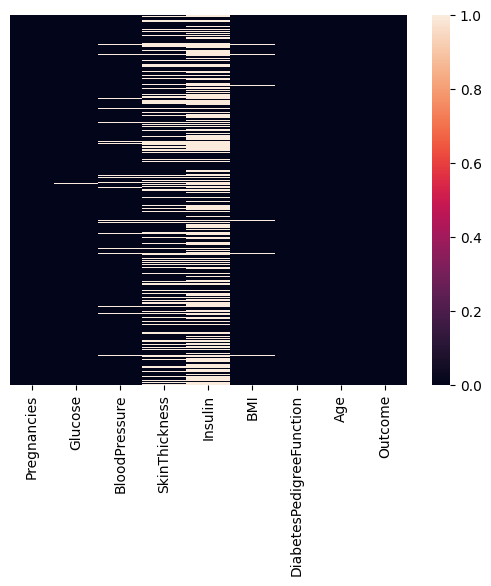

In [12]:
sns.heatmap(data.isnull(), yticklabels= False)

In [13]:
df_pima = data
df_pima.shape

(768, 9)

In [14]:
df_pima.isnull().sum()

,0
Pregnancies,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [15]:
from sklearn.experimental import enable_iterative_imputer  # Perlu diaktifkan terlebih dahulu
from sklearn.impute import IterativeImputer

In [16]:
mice = IterativeImputer() #Buat nambah missing value, inputnya by prediksi angka angka terdekat, alasannya agar prediksinya lebih rasional

In [17]:
df_pima[["Insulin", "SkinThickness", "Glucose", "BloodPressure", "BMI"]] = mice.fit_transform(df_pima[["Insulin","SkinThickness", "Glucose", "BloodPressure", "BMI"]])

In [18]:
df_pima.isnull().sum() # HASIL YANG UDAH DI TRANSFORM

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


<Axes: >

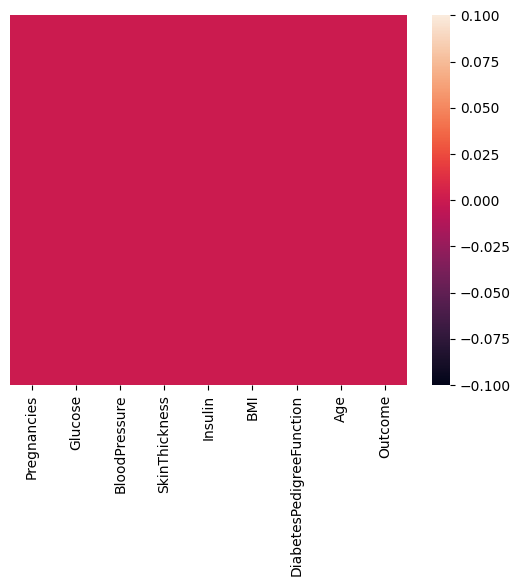

In [19]:
sns.heatmap(df_pima.isnull(), yticklabels= False)

<Axes: xlabel='Outcome', ylabel='count'>

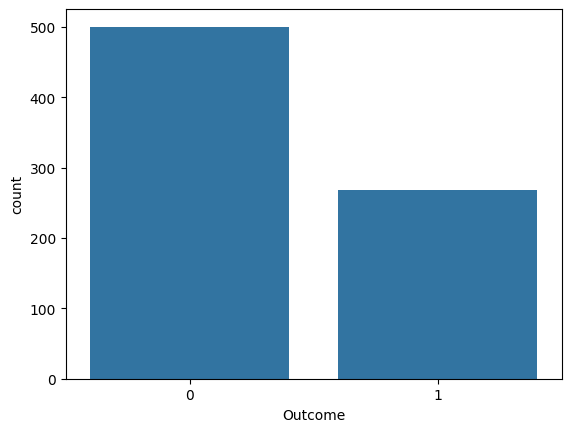

In [20]:
sns.countplot(x = 'Outcome', data = df_pima)

,0
Pregnancies,"Axes(0.125,0.653529;0.227941x0.226471)"
Glucose,"Axes(0.398529,0.653529;0.227941x0.226471)"
BloodPressure,"Axes(0.672059,0.653529;0.227941x0.226471)"
SkinThickness,"Axes(0.125,0.381765;0.227941x0.226471)"
Insulin,"Axes(0.398529,0.381765;0.227941x0.226471)"
BMI,"Axes(0.672059,0.381765;0.227941x0.226471)"
DiabetesPedigreeFunction,"Axes(0.125,0.11;0.227941x0.226471)"
Age,"Axes(0.398529,0.11;0.227941x0.226471)"
Outcome,"Axes(0.672059,0.11;0.227941x0.226471)"


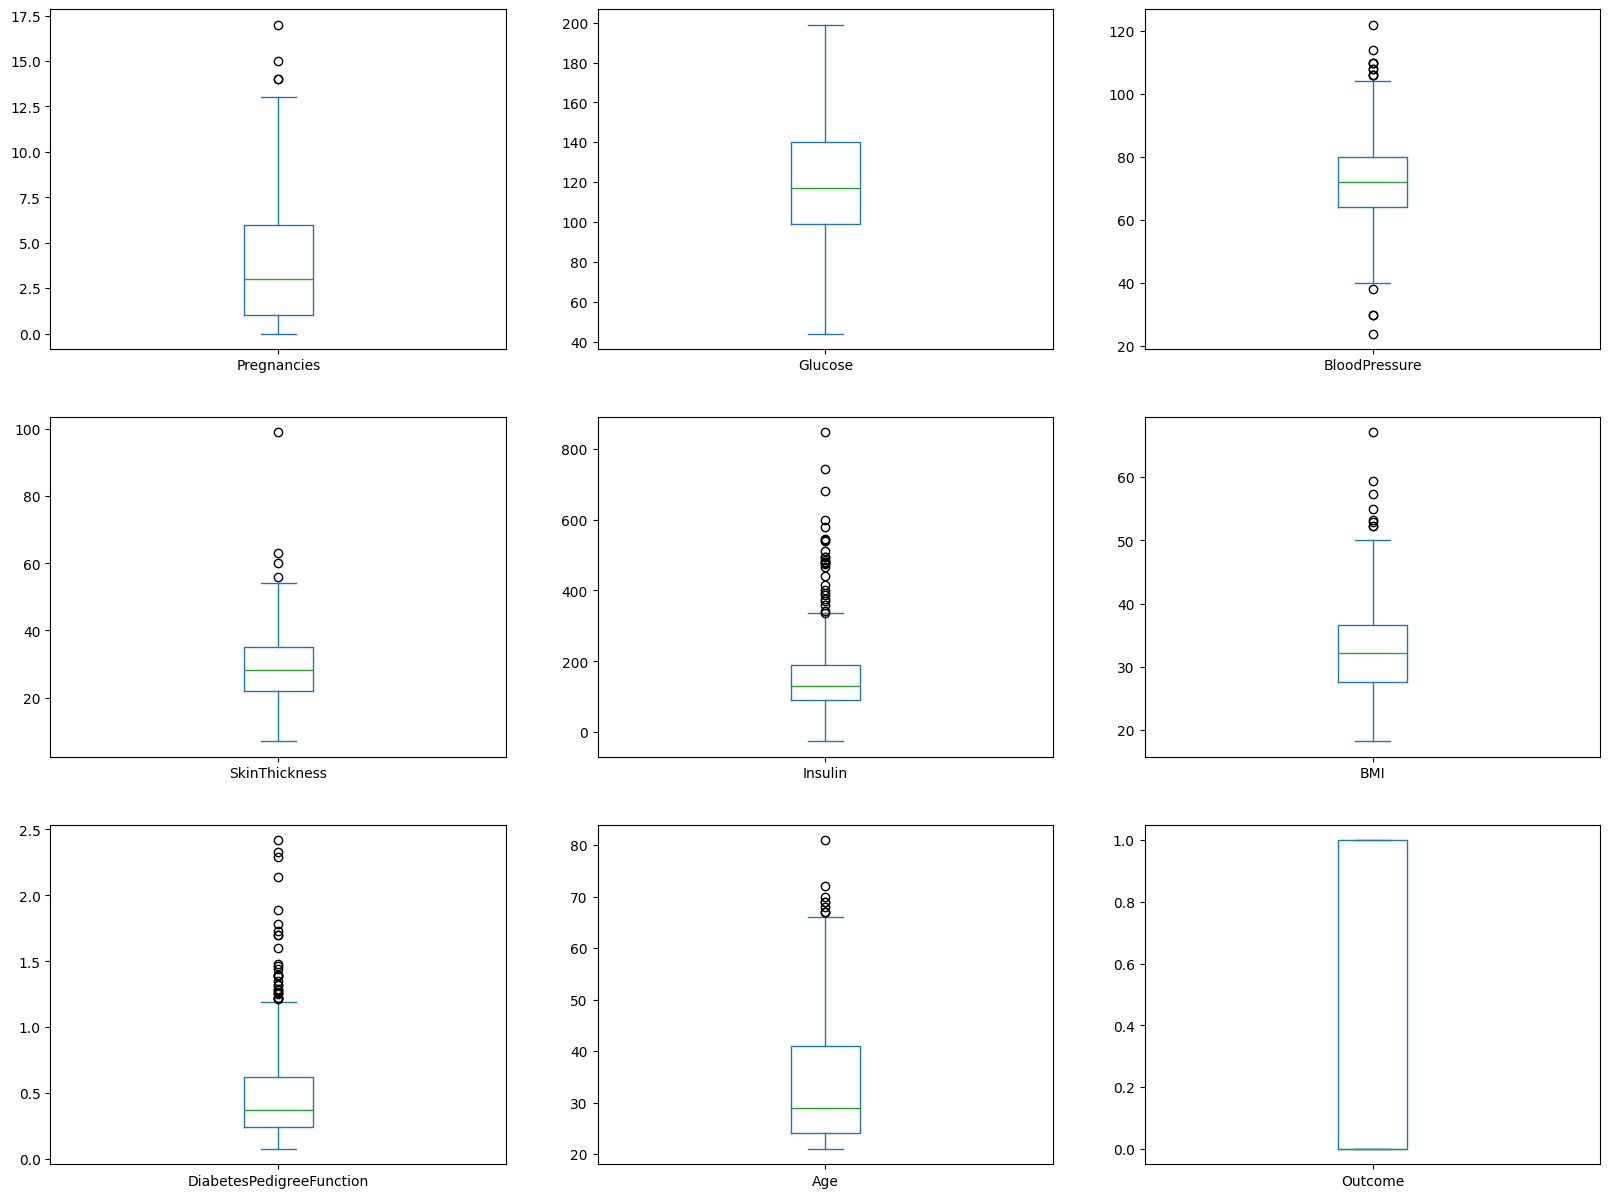

In [21]:
#Box and Whisker plot to visualize the distribution of all atributes
df_pima.plot(kind= 'box',subplots=True, layout=(3,3), sharex=False, sharey=False, figsize=(20,15))

In [22]:
# outlier/anomaly detection
from sklearn.neighbors import LocalOutlierFactor #Buat ngapus data yang noise

In [23]:
# model specification
model1 = LocalOutlierFactor(n_neighbors=10)
# model fitting
y_pred = model1.fit_predict(df_pima)
# filter outlier index
not_outlier_index = np.where(y_pred == 1)
outlier_index = np.where(y_pred == -1)# negative values are outliers and positives inliers
# filter outlier values
df_pima_1 = df_pima.iloc[not_outlier_index]

,0
Pregnancies,"Axes(0.125,0.653529;0.227941x0.226471)"
Glucose,"Axes(0.398529,0.653529;0.227941x0.226471)"
BloodPressure,"Axes(0.672059,0.653529;0.227941x0.226471)"
SkinThickness,"Axes(0.125,0.381765;0.227941x0.226471)"
Insulin,"Axes(0.398529,0.381765;0.227941x0.226471)"
BMI,"Axes(0.672059,0.381765;0.227941x0.226471)"
DiabetesPedigreeFunction,"Axes(0.125,0.11;0.227941x0.226471)"
Age,"Axes(0.398529,0.11;0.227941x0.226471)"
Outcome,"Axes(0.672059,0.11;0.227941x0.226471)"


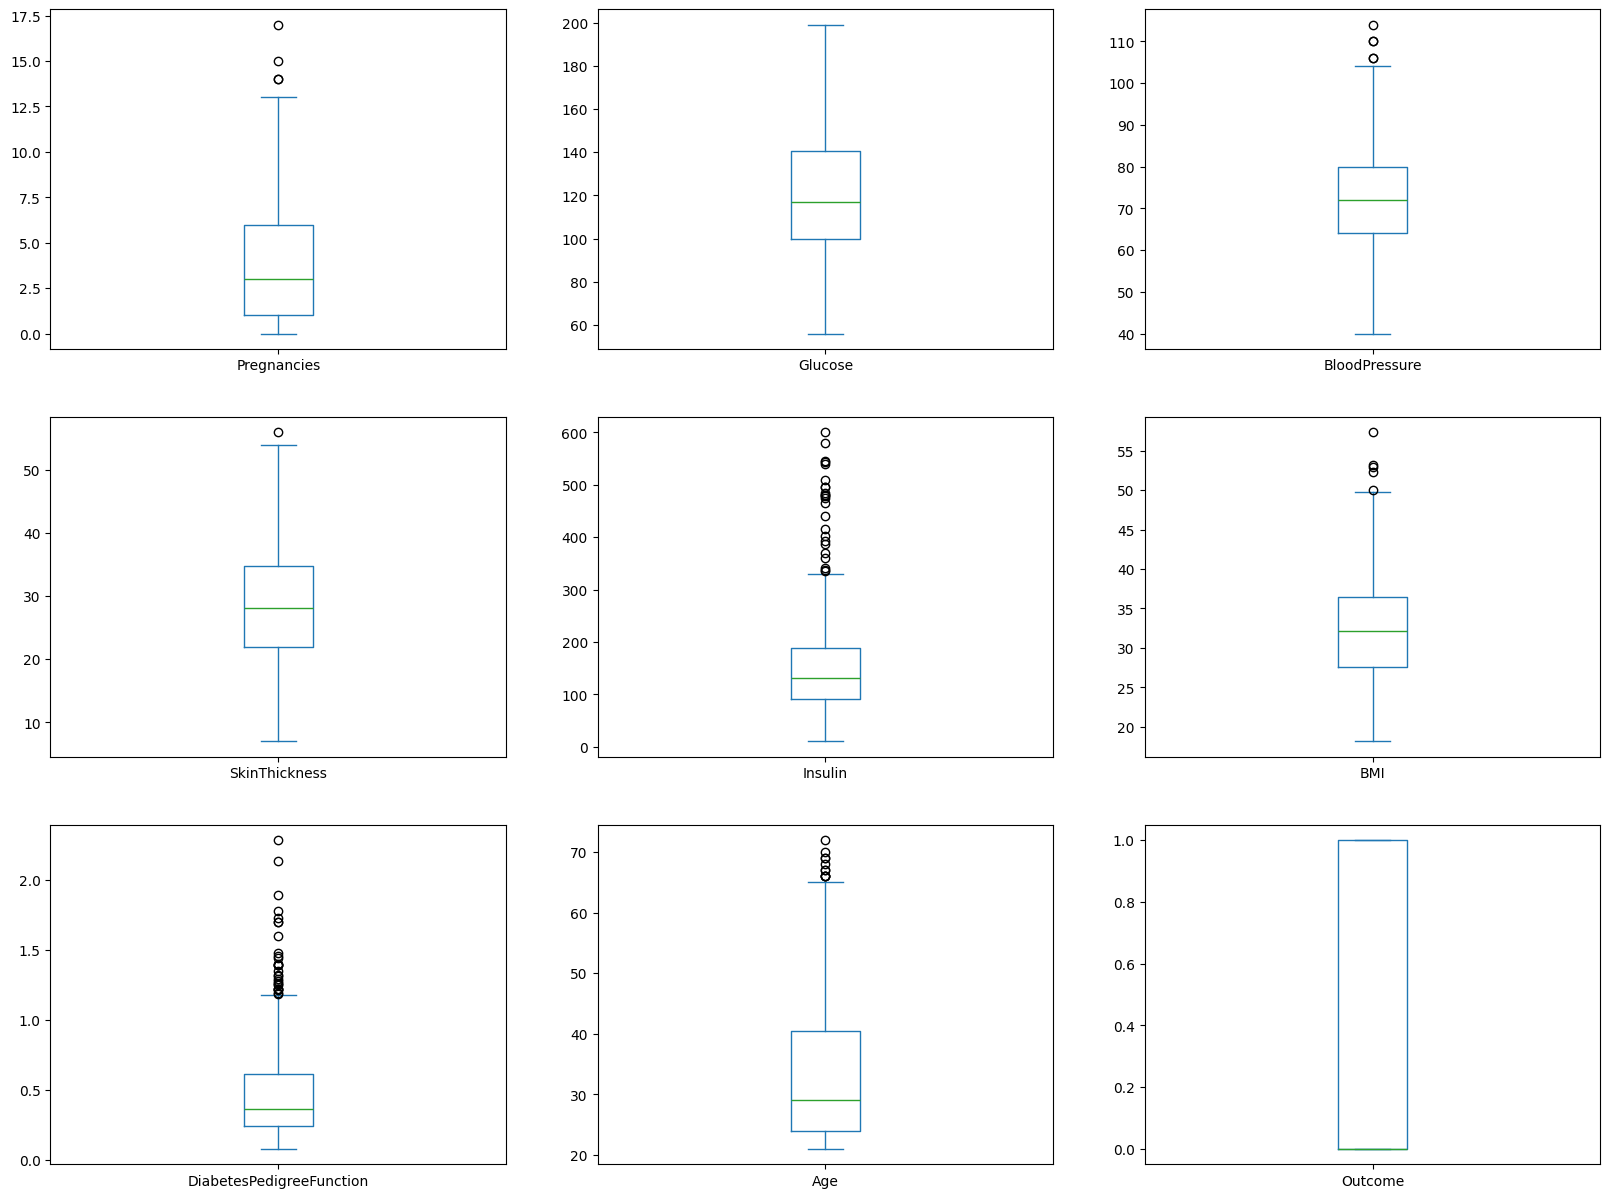

In [24]:
#Box and Whisker plot to visualize the distribution of all atributes
df_pima_1.plot(kind= 'box',subplots=True, layout=(3,3), sharex=False, sharey=False, figsize=(20,15))

In [25]:
df_pima

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.000000,212.347446,33.6,0.627,50,1
1,1,85.0,66.0,29.000000,66.407208,26.6,0.351,31,0
2,8,183.0,64.0,21.486494,272.954432,23.3,0.672,32,1
3,1,89.0,66.0,23.000000,94.000000,28.1,0.167,21,0
4,0,137.0,40.0,35.000000,168.000000,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101.0,76.0,48.000000,180.000000,32.9,0.171,63,0
764,2,122.0,70.0,27.000000,159.879349,36.8,0.340,27,0
765,5,121.0,72.0,23.000000,112.000000,26.2,0.245,30,0
766,1,126.0,60.0,26.461215,162.793546,30.1,0.349,47,1


In [26]:
df_pima_1

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.000000,212.347446,33.6,0.627,50,1
1,1,85.0,66.0,29.000000,66.407208,26.6,0.351,31,0
2,8,183.0,64.0,21.486494,272.954432,23.3,0.672,32,1
3,1,89.0,66.0,23.000000,94.000000,28.1,0.167,21,0
4,0,137.0,40.0,35.000000,168.000000,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101.0,76.0,48.000000,180.000000,32.9,0.171,63,0
764,2,122.0,70.0,27.000000,159.879349,36.8,0.340,27,0
765,5,121.0,72.0,23.000000,112.000000,26.2,0.245,30,0
766,1,126.0,60.0,26.461215,162.793546,30.1,0.349,47,1


In [27]:
df_pima_1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 743 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               743 non-null    int64  
 1   Glucose                   743 non-null    float64
 2   BloodPressure             743 non-null    float64
 3   SkinThickness             743 non-null    float64
 4   Insulin                   743 non-null    float64
 5   BMI                       743 non-null    float64
 6   DiabetesPedigreeFunction  743 non-null    float64
 7   Age                       743 non-null    int64  
 8   Outcome                   743 non-null    int64  
dtypes: float64(6), int64(3)
memory usage: 58.0 KB


In [28]:
df_pima.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    float64
 2   BloodPressure             768 non-null    float64
 3   SkinThickness             768 non-null    float64
 4   Insulin                   768 non-null    float64
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(6), int64(3)
memory usage: 54.1 KB


In [29]:
df_pima_SMOTETOMEK = df_pima_1

In [30]:
X = df_pima_1.drop(columns=["Outcome"])
y = df_pima_1['Outcome']

In [117]:
X_train, X_test, y_train, y_test = train_test_split(X, y,  test_size= 0.20, random_state=42, stratify= y)
print("data training =", X_train.shape)
print("data training =", X_test.shape)

data training = (594, 8)
data training = (149, 8)


# Stacking Ensemble random forest x XG boost

In [32]:
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn import metrics
import xgboost as xgb
import pandas as pd

In [33]:
base_models = [
    ('rf', RandomForestClassifier(n_estimators=100, random_state=42)),
    ('xgb', xgb.XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42))
]

In [34]:
meta_model = LogisticRegression()

In [35]:
clf_stacking = StackingClassifier(
    estimators=base_models,
    final_estimator=meta_model,
    cv=5
)

In [36]:
print("[INFO] Melatih model Stacking Ensemble (RF x XGB)")
clf_stacking.fit(X_train, y_train)

[INFO] Melatih model Stacking Ensemble (RF x XGB)


StackingClassifier(cv=5,
                   estimators=[('rf', RandomForestClassifier(random_state=42)),
                               ('xgb',
                                XGBClassifier(base_score=None, booster=None,
                                              callbacks=None,
                                              colsample_bylevel=None,
                                              colsample_bynode=None,
                                              colsample_bytree=None,
                                              device=None,
                                              early_stopping_rounds=None,
                                              enable_categorical=True,
                                              eval_metric='logloss',
                                              feature_types=None,
                                              feature_weights=None, gamma=None...
                                              importance_type=None,
                                              interaction_constraints=None,
                                              learning_rate=None, max_bin=None,
                                              max_cat_threshold=None,
                                              max_cat_to_onehot=None,
                                              max_delta_step=None,
                                              max_depth=None, max_leaves=None,
                                              min_child_weight=None,
                                              missing=nan,
                                              monotone_constraints=None,
                                              multi_strategy=None,
                                              n_estimators=None, n_jobs=None,
                                              num_parallel_tree=None, ...))],
                   final_estimator=LogisticRegression())

In [37]:
y_pred_stacking = clf_stacking.predict(X_test)

In [38]:
print("\n" + metrics.accuracy_score.__name__.upper() + " METRICS")
acc_score = metrics.accuracy_score(y_test, y_pred_stacking)
print(f"Accuracy : {acc_score:.6f}")
print("-" * 50)


ACCURACY_SCORE METRICS
Accuracy : 0.738255
--------------------------------------------------


In [39]:
print("\nOTHER KEY METRICS")
print(f"Precision: {metrics.precision_score(y_test, y_pred_stacking):.6f}")
print(f"Recall   : {metrics.recall_score(y_test, y_pred_stacking):.6f}")
print(f"F1 Score : {metrics.f1_score(y_test, y_pred_stacking):.6f}")
print("-" * 50)


OTHER KEY METRICS
Precision: 0.666667
Recall   : 0.500000
F1 Score : 0.571429
--------------------------------------------------


In [40]:
print("\nCLASSIFICATION REPORT")
print(metrics.classification_report(y_test, y_pred_stacking))
print("-" * 50)


CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.76      0.87      0.81        97
           1       0.67      0.50      0.57        52

    accuracy                           0.74       149
   macro avg       0.72      0.68      0.69       149
weighted avg       0.73      0.74      0.73       149

--------------------------------------------------


In [41]:
cm_stacking = metrics.confusion_matrix(y_test, y_pred_stacking)

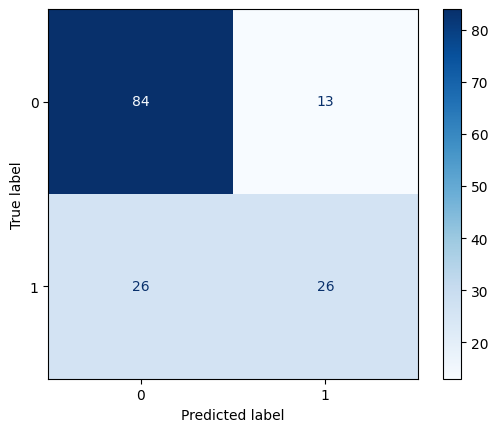

In [42]:
disp = metrics.ConfusionMatrixDisplay(confusion_matrix=cm_stacking)
disp.plot(cmap='Blues', values_format='d')

# Smote x Stacking

In [118]:
print("Before OverSampling, counts of label '1': {}".format(sum(y_train == 1)))
print("Before OverSampling, counts of label '0': {} \n".format(sum(y_train == 0)))

Before OverSampling, counts of label '1': 209
Before OverSampling, counts of label '0': 385 



In [119]:
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
import xgboost as xgb

In [120]:
sm = SMOTE(random_state=0)
X_SMOTE, y_SMOTE = sm.fit_resample(X_train, y_train.ravel())

In [121]:
data_SMOTE = pd.DataFrame(X_SMOTE, columns=X_train.columns)

In [122]:
datay_SMOTE = pd.DataFrame(y_SMOTE)

In [123]:
df_SMOTE = pd.concat([data_SMOTE, datay_SMOTE], axis=1)

In [124]:
df_SMOTE

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,0
0,5,95.000000,72.000000,33.000000,103.230192,37.700000,0.370000,27,0
1,0,105.000000,90.000000,25.986281,102.582526,29.600000,0.197000,46,0
2,11,138.000000,74.000000,26.000000,144.000000,36.100000,0.557000,50,1
3,6,105.000000,70.000000,32.000000,68.000000,30.800000,0.122000,37,0
4,0,91.000000,68.000000,32.000000,210.000000,39.900000,0.381000,25,0
...,...,...,...,...,...,...,...,...,...
765,3,166.042099,68.443465,30.778268,327.221732,34.384483,0.406002,33,1
766,1,119.121439,74.766616,35.431840,161.058581,39.685207,0.509832,25,1
767,4,130.824801,81.175199,33.591089,175.992624,37.161718,0.727530,39,1
768,7,144.091288,68.728219,32.726898,208.697074,36.127699,0.163921,41,1


In [125]:
X_train, X_test, y_train, y_test = train_test_split(X_SMOTE, y_SMOTE, random_state=42, test_size= 0.20)

In [126]:
print("data training =", X_train.shape)
print("data training =", X_test.shape)

data training = (616, 8)
data training = (154, 8)


In [127]:
base_models = [
    ('rf', RandomForestClassifier(random_state=42)),
    ('xgb', xgb.XGBClassifier(random_state=42))
]

In [128]:
meta_model = LogisticRegression()

In [129]:
clf = StackingClassifier(
    estimators=base_models,
    final_estimator=meta_model,
    cv=5
)

In [130]:
clf.fit(X_train,y_train)

StackingClassifier(cv=5,
                   estimators=[('rf', RandomForestClassifier(random_state=42)),
                               ('xgb',
                                XGBClassifier(base_score=None, booster=None,
                                              callbacks=None,
                                              colsample_bylevel=None,
                                              colsample_bynode=None,
                                              colsample_bytree=None,
                                              device=None,
                                              early_stopping_rounds=None,
                                              enable_categorical=True,
                                              eval_metric=None,
                                              feature_types=None,
                                              feature_weights=None, gamma=None,
                                              grow...
                                              importance_type=None,
                                              interaction_constraints=None,
                                              learning_rate=None, max_bin=None,
                                              max_cat_threshold=None,
                                              max_cat_to_onehot=None,
                                              max_delta_step=None,
                                              max_depth=None, max_leaves=None,
                                              min_child_weight=None,
                                              missing=nan,
                                              monotone_constraints=None,
                                              multi_strategy=None,
                                              n_estimators=None, n_jobs=None,
                                              num_parallel_tree=None, ...))],
                   final_estimator=LogisticRegression())

In [131]:
y_pred = clf.predict(X_test)

In [132]:
print('After OverSampling, the shape of train_X: {}'.format(X_SMOTE.shape))
print('After OverSampling, the shape of train_y: {} \n'.format(y_SMOTE.shape))

print("After OverSampling, counts of label '1': {}".format(sum(y_SMOTE == 1)))
print("After OverSampling, counts of label '0': {}".format(sum(y_SMOTE == 0)))

After OverSampling, the shape of train_X: (770, 8)
After OverSampling, the shape of train_y: (770,) 

After OverSampling, counts of label '1': 385
After OverSampling, counts of label '0': 385


In [133]:
from sklearn import metrics

print("Accuracy:", metrics.accuracy_score(y_test, y_pred))
accSmote = metrics.accuracy_score(y_test, y_pred)

Accuracy: 0.8376623376623377


In [134]:
from sklearn.metrics import precision_score

print(precision_score(y_test, y_pred))

0.8160919540229885


In [135]:
from sklearn.metrics import recall_score

print(recall_score(y_test, y_pred))

0.8875


In [136]:
from sklearn.metrics import f1_score

print('F1 Score: %.3f' % f1_score(y_test, y_pred))

F1 Score: 0.850


In [137]:
scoreSMOTERandomForestXGBoost = metrics.accuracy_score(y_test, y_pred)

In [138]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.87      0.78      0.82        74
           1       0.82      0.89      0.85        80

    accuracy                           0.84       154
   macro avg       0.84      0.84      0.84       154
weighted avg       0.84      0.84      0.84       154



              precision    recall  f1-score   support

           0       0.87      0.78      0.82        74
           1       0.82      0.89      0.85        80

    accuracy                           0.84       154
   macro avg       0.84      0.84      0.84       154
weighted avg       0.84      0.84      0.84       154



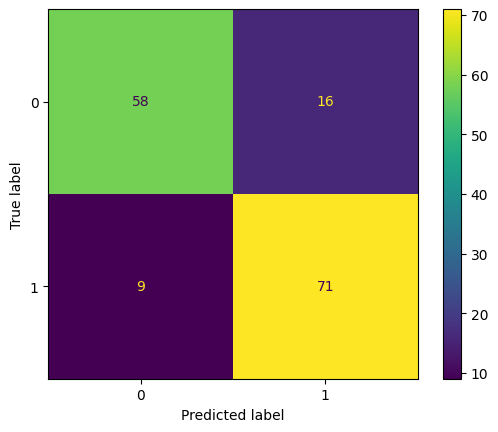

In [139]:
print(classification_report(y_test, y_pred))
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.show()

# SMOTETOMEK x STACKING ENSEMBLE RANDOM FOREST dan XG BOOST

In [94]:
print("Before OverSampling, counts of label '1': {}".format(sum(y_train == 1)))
print("Before OverSampling, counts of label '0': {} \n".format(sum(y_train == 0)))

Before OverSampling, counts of label '1': 209
Before OverSampling, counts of label '0': 385 



In [95]:
from imblearn.combine import SMOTETomek
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn import metrics
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
import xgboost as xgb

In [96]:
sm = SMOTETomek(random_state=0)
X_SMOTETOMEK, y_SMOTETOMEK = sm.fit_resample(X_train, y_train.ravel())

In [97]:
data_SMOTETOMEK = pd.DataFrame(X_SMOTETOMEK, columns=X_SMOTETOMEK.columns)

In [98]:
datay_SMOTETOMEK = pd.DataFrame(y_SMOTETOMEK)

In [99]:
df_SMOTETOMEK = pd.concat([data_SMOTETOMEK, datay_SMOTETOMEK], axis=1)

In [100]:
df_SMOTETOMEK

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,0
0,5,95.000000,72.000000,33.000000,103.230192,37.700000,0.370000,27,0
1,0,105.000000,90.000000,25.986281,102.582526,29.600000,0.197000,46,0
2,11,138.000000,74.000000,26.000000,144.000000,36.100000,0.557000,50,1
3,6,105.000000,70.000000,32.000000,68.000000,30.800000,0.122000,37,0
4,0,91.000000,68.000000,32.000000,210.000000,39.900000,0.381000,25,0
...,...,...,...,...,...,...,...,...,...
747,3,166.042099,68.443465,30.778268,327.221732,34.384483,0.406002,33,1
748,1,119.121439,74.766616,35.431840,161.058581,39.685207,0.509832,25,1
749,4,130.824801,81.175199,33.591089,175.992624,37.161718,0.727530,39,1
750,7,144.091288,68.728219,32.726898,208.697074,36.127699,0.163921,41,1


In [101]:
X_train, X_test, y_train, y_test = train_test_split(X_SMOTETOMEK, y_SMOTETOMEK, random_state=42, test_size= 0.20)

In [102]:
print("data training =", X_train.shape)
print("data training =", X_test.shape)

data training = (601, 8)
data training = (151, 8)


In [103]:
base_models = [
    ('rf', RandomForestClassifier(random_state=42)),
    ('xgb', xgb.XGBClassifier(random_state=42))
]

In [104]:
meta_model = LogisticRegression()

In [106]:
clf = StackingClassifier(
    estimators=base_models,
    final_estimator=meta_model,
    cv=5
)

In [107]:
clf.fit(X_train, y_train)

StackingClassifier(cv=5,
                   estimators=[('rf', RandomForestClassifier(random_state=42)),
                               ('xgb',
                                XGBClassifier(base_score=None, booster=None,
                                              callbacks=None,
                                              colsample_bylevel=None,
                                              colsample_bynode=None,
                                              colsample_bytree=None,
                                              device=None,
                                              early_stopping_rounds=None,
                                              enable_categorical=True,
                                              eval_metric=None,
                                              feature_types=None,
                                              feature_weights=None, gamma=None,
                                              grow...
                                              importance_type=None,
                                              interaction_constraints=None,
                                              learning_rate=None, max_bin=None,
                                              max_cat_threshold=None,
                                              max_cat_to_onehot=None,
                                              max_delta_step=None,
                                              max_depth=None, max_leaves=None,
                                              min_child_weight=None,
                                              missing=nan,
                                              monotone_constraints=None,
                                              multi_strategy=None,
                                              n_estimators=None, n_jobs=None,
                                              num_parallel_tree=None, ...))],
                   final_estimator=LogisticRegression())

In [108]:
y_pred = clf.predict(X_test)

In [109]:
print('After OverSampling, the shape of train_X: {}'.format(X_SMOTETOMEK.shape))
print('After OverSampling, the shape of train_y: {} \n'.format(y_SMOTETOMEK.shape))

print("After OverSampling, counts of label '1': {}".format(sum(y_SMOTETOMEK == 1)))
print("After OverSampling, counts of label '0': {}".format(sum(y_SMOTETOMEK == 0)))

After OverSampling, the shape of train_X: (752, 8)
After OverSampling, the shape of train_y: (752,) 

After OverSampling, counts of label '1': 376
After OverSampling, counts of label '0': 376


In [110]:
print("Accuracy:", metrics.accuracy_score(y_test, y_pred))
accSmotetomek = metrics.accuracy_score(y_test, y_pred)

Accuracy: 0.8675496688741722


In [111]:
print("Accuracy:", metrics.accuracy_score(y_test, y_pred))

Accuracy: 0.8675496688741722


In [112]:
print(precision_score(y_test, y_pred))

0.8607594936708861


In [113]:
print(recall_score(y_test, y_pred))

0.8831168831168831


In [114]:
print('F1 Score: %.3f' % f1_score(y_test, y_pred))

F1 Score: 0.872


In [115]:
scoreSMOTETOMEKRandomForestXGBoost = metrics.accuracy_score(y_test, y_pred)

              precision    recall  f1-score   support

           0       0.88      0.85      0.86        74
           1       0.86      0.88      0.87        77

    accuracy                           0.87       151
   macro avg       0.87      0.87      0.87       151
weighted avg       0.87      0.87      0.87       151



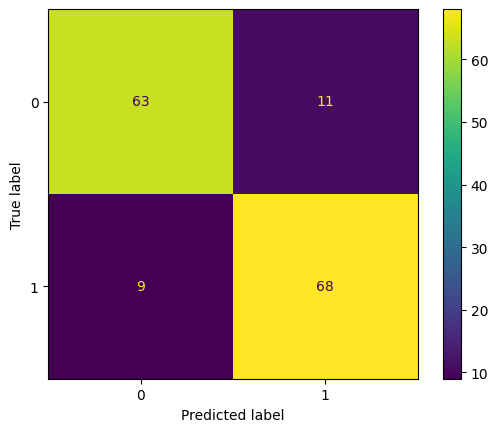

In [116]:
print(classification_report(y_test, y_pred))
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.show()

**Pembuatan Model**